# ProductPulse - Data cleaning and generation

Build the four PostgreSQL tables from the IBM Telco Customer Churn CSV: `users`, `events`, `subscriptions`, and `payments`. Customer attributes come from the source; product activity, trial-only accounts, and lifecycle histories are derived or simulated.

The [data dictionary](../docs/data_dictionary.md) documents the field mappings and generation parameters.


**Data scope:** Usage histories and lifecycle dates are reconstructed or simulated using churn outcomes. See the [methodology and known issues](../docs/project_review.md) when interpreting results.

## Setup

In [15]:
import os
import time

import numpy as np
import pandas as pd

t0 = time.time()

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

# Simulation parameters; see docs/data_dictionary.md.
SNAPSHOT_DATE = pd.Timestamp('2026-08-31')   # the fictional "as of" date
TRIAL_LENGTH_DAYS = 14
NON_CONVERTER_RATE = 0.30  # Trial-only accounts as a fraction of source customers.

RAW_PATH = '../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv'
OUT_DIR = '../data/processed'

# --- Synthetic attribute catalogs ---
COUNTRIES = ['United States', 'United Kingdom', 'India', 'Canada', 'Australia',
             'Germany', 'France', 'Brazil', 'Netherlands', 'Singapore']
COUNTRY_WEIGHTS = [0.42, 0.12, 0.10, 0.08, 0.06, 0.06, 0.05, 0.04, 0.04, 0.03]

CHANNELS = ['Organic Search', 'Paid Search', 'Paid Social', 'Referral', 'Partner', 'Email']
# Mild, documented skew: users who end up churning were sourced a little more
# from paid channels; users who stay active a little more from organic/referral.
CHANNEL_WEIGHTS_CHURNED = [0.22, 0.27, 0.23, 0.10, 0.10, 0.08]
CHANNEL_WEIGHTS_ACTIVE  = [0.32, 0.18, 0.14, 0.18, 0.10, 0.08]

FEATURES = ['Dashboard', 'Reports', 'Integrations', 'TeamManagement', 'API',
            'Notifications', 'Exports', 'Search', 'Billing', 'Settings']
FEATURE_WEIGHTS = [0.24, 0.20, 0.12, 0.10, 0.09, 0.08, 0.06, 0.06, 0.03, 0.02]  # power-law-ish popularity

# Weekly session rates for the full reconstructed history.
PLAN_BASE_SESSIONS_PER_WEEK = {'Basic': 0.35, 'Pro': 0.7, 'Enterprise': 1.2}


## Step 1 - Load and clean the source data

Eleven zero-tenure customers have blank `TotalCharges`. Convert these blanks to numeric missing values and fill them with zero, preserving the customer records.


In [17]:
raw = pd.read_csv(RAW_PATH)
raw['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce').fillna(0.0)
assert raw['customerID'].is_unique, "duplicate customerID in source data"

n_real = len(raw)
print(f"Loaded {n_real} real customers, {raw.shape[1]} columns")
raw.head()


Loaded 7043 real customers, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2 - Reconstruct signup dates

The source records tenure in months but contains no signup dates. Derive active customers' dates backward from the snapshot. For churned customers, first assign an earlier end date, then subtract tenure. Add day-level jitter and sample country and acquisition-channel categories. Channel weights depend on the churn label.


In [18]:
is_churn_real = (raw['Churn'].values == 'Yes')
COMPANY_START = SNAPSHOT_DATE - pd.DateOffset(months=72)  # matches the longest real tenure

def compute_signup_date(tenure, is_churn, u):
    tenure = int(tenure)
    if is_churn:
        earliest_churn = COMPANY_START + pd.DateOffset(months=tenure)
        span_days = max((SNAPSHOT_DATE - earliest_churn).days, 0)
        churn_date = earliest_churn + pd.Timedelta(days=int(u * span_days))
        return churn_date - pd.DateOffset(months=tenure)
    return SNAPSHOT_DATE - pd.DateOffset(months=tenure)

uniform_draws = rng.random(n_real)
signup_base = pd.Series([
    compute_signup_date(t, c, u)
    for t, c, u in zip(raw['tenure'].values, is_churn_real, uniform_draws)
])
jitter = rng.integers(-10, 11, size=n_real)
real_signup_date = (signup_base + pd.to_timedelta(jitter, unit='D')).clip(upper=SNAPSHOT_DATE)

country_real = rng.choice(COUNTRIES, size=n_real, p=COUNTRY_WEIGHTS)
channel_if_churned = rng.choice(CHANNELS, size=n_real, p=CHANNEL_WEIGHTS_CHURNED)
channel_if_active  = rng.choice(CHANNELS, size=n_real, p=CHANNEL_WEIGHTS_ACTIVE)
channel_real = np.where(is_churn_real, channel_if_churned, channel_if_active)

users_real = pd.DataFrame({
    'user_id': raw['customerID'].values,
    'signup_date': real_signup_date.dt.date,
    'country': country_real,
    'acquisition_channel': channel_real,
})
users_real.head()


,user_id,signup_date,country,acquisition_channel
0,7590-VHVEG,2026-07-30,United Kingdom,Referral
1,5575-GNVDE,2023-10-25,United States,Organic Search
2,3668-QPYBK,2025-08-25,Germany,Organic Search
3,7795-CFOCW,2022-12-10,United States,Partner
4,9237-HQITU,2021-03-29,Netherlands,Paid Search


## Step 3 - Add trial-only accounts

Add 2,113 simulated non-converting accounts, equal to 30% of the source population. Sample their signup dates from the reconstructed signup distribution and generate unique IDs. The resulting signup-to-paid ratio is set by this construction.


In [19]:
n_nc = int(round(n_real * NON_CONVERTER_RATE))

def gen_synthetic_ids(existing, n, rng):
    letters = np.array(list('ABCDEFGHIJKLMNOPQRSTUVWXYZ'))
    ids = set()
    while len(ids) < n:
        need = n - len(ids)
        digits = rng.integers(1000, 10000, size=need)
        suffixes = [''.join(rng.choice(letters, size=5)) for _ in range(need)]
        candidates = {f"{d}-{s}" for d, s in zip(digits, suffixes)}
        ids |= (candidates - existing)
    return sorted(ids)[:n]

existing_ids = set(raw['customerID'])
nc_ids = gen_synthetic_ids(existing_ids, n_nc, rng)

base_idx = rng.integers(0, n_real, size=n_nc)
nc_base_dates = real_signup_date.iloc[base_idx].reset_index(drop=True)
nc_jitter = rng.integers(-5, 6, size=n_nc)
nc_signup_date = (nc_base_dates + pd.to_timedelta(nc_jitter, unit='D')).clip(upper=SNAPSHOT_DATE)

country_nc = rng.choice(COUNTRIES, size=n_nc, p=COUNTRY_WEIGHTS)
channel_nc = rng.choice(CHANNELS, size=n_nc, p=CHANNEL_WEIGHTS_CHURNED)  # never-converted -> "churned" cohort

users_nc = pd.DataFrame({
    'user_id': nc_ids,
    'signup_date': nc_signup_date.dt.date,
    'country': country_nc,
    'acquisition_channel': channel_nc,
})

users = pd.concat([users_real, users_nc], ignore_index=True)
print(f"{n_real} real + {n_nc} synthetic non-converters = {len(users)} total users")
print(f"implied trial->paid conversion: {n_real/len(users):.1%}")


7043 real + 2113 synthetic non-converters = 9156 total users
implied trial->paid conversion: 76.9%


## Step 4 - Build subscriptions

Map monthly-charge terciles to plan tiers and the source churn label to snapshot status. Paid dates are derived from signup plus the assumed trial length; they are not observed source dates.


In [20]:
# Plan tiers use source MonthlyCharges terciles.
q1, q2 = raw['MonthlyCharges'].quantile([1/3, 2/3])

def plan_from_charge(x):
    if x <= q1:
        return 'Basic'
    if x <= q2:
        return 'Pro'
    return 'Enterprise'

plan_real = raw['MonthlyCharges'].apply(plan_from_charge).values
status_real = np.where(is_churn_real, 'churned', 'active')     # real Churn flag, direct mapping
trial_start_real = real_signup_date.dt.date
paid_date_real_ts = real_signup_date + pd.to_timedelta(TRIAL_LENGTH_DAYS, unit='D')
paid_date_real = paid_date_real_ts.dt.date

subs_real = pd.DataFrame({
    'user_id': raw['customerID'].values,
    'plan': plan_real,
    'status': status_real,
    'trial_start': trial_start_real,
    'paid_date': paid_date_real,
})

# Trial-only accounts have no paid date and use a Basic-weighted plan mix.
NC_PLAN_WEIGHTS = [0.55, 0.32, 0.13]
plan_nc = rng.choice(['Basic', 'Pro', 'Enterprise'], size=n_nc, p=NC_PLAN_WEIGHTS)

subs_nc = pd.DataFrame({
    'user_id': nc_ids,
    'plan': plan_nc,
    'status': 'churned',
    'trial_start': nc_signup_date.dt.date,
    'paid_date': pd.NaT,
})

subscriptions = pd.concat([subs_real, subs_nc], ignore_index=True)
subscriptions.groupby(['status'])['paid_date'].agg(users='count', converted='count')


,users,converted
status,,
active,5174,5174
churned,1869,1869


## Step 5 - Reconstruct payments

Create monthly payment rows using source tenure and monthly charges, bounded by the reporting snapshot. Compare reconstructed totals with `TotalCharges` as a consistency check. The source does not contain individual invoices.


In [21]:
pay_records = []
pid = 1
for cid, tenure, charge, pdate in zip(raw['customerID'].values, raw['tenure'].values,
                                       raw['MonthlyCharges'].values, paid_date_real_ts):
    n_pay = max(int(tenure), 0)
    for i in range(n_pay):
        pay_date = pdate + pd.DateOffset(months=i)
        if pay_date > SNAPSHOT_DATE:
            break
        pay_records.append((pid, cid, round(float(charge), 2), pay_date.date()))
        pid += 1

payments = pd.DataFrame(pay_records, columns=['payment_id', 'user_id', 'amount', 'payment_date'])
print(f"{len(payments)} payment rows for {payments['user_id'].nunique()} paying users")


227990 payment rows for 7032 paying users


QA — reconstructed vs. real TotalCharges per user
correlation: 0.9996
count    7043.000000
mean       45.018735
std        49.892509
min         0.000000
25%         9.350000
50%        28.600000
75%        63.625000
max       373.250000
dtype: float64


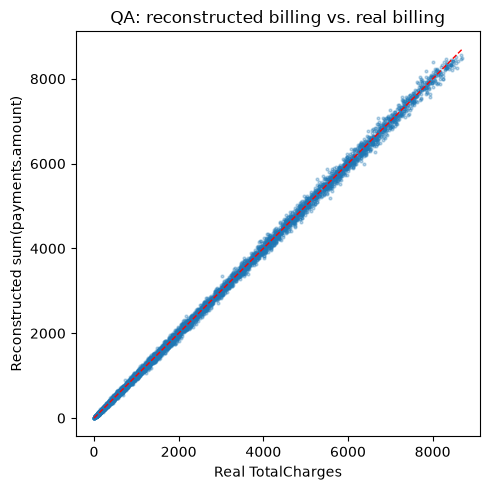

In [22]:
import matplotlib.pyplot as plt

recon = payments.groupby('user_id')['amount'].sum().reindex(raw['customerID']).fillna(0.0).values
qa = pd.DataFrame({'real_total': raw['TotalCharges'].values, 'reconstructed_total': recon})

print("QA — reconstructed vs. real TotalCharges per user")
print(f"correlation: {qa['real_total'].corr(qa['reconstructed_total']):.4f}")
print((qa['real_total'] - qa['reconstructed_total']).abs().describe())

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(qa['real_total'], qa['reconstructed_total'], s=4, alpha=0.3)
ax.plot([0, qa['real_total'].max()], [0, qa['real_total'].max()], 'r--', linewidth=1)
ax.set_xlabel('Real TotalCharges')
ax.set_ylabel('Reconstructed sum(payments.amount)')
ax.set_title('QA: reconstructed billing vs. real billing')
plt.tight_layout()
plt.show()


## Step 6 - Simulate product events

Generate sessions across each reconstructed activity history. Rates vary by plan and engagement level; activity tapers near assigned churn dates. Feature usage is sampled from a weighted catalog.

The dependence on churn outcomes is a modelling assumption. Any resulting engagement-churn relationship must be interpreted within that simulation.


In [23]:
def compute_effective_end(paid_ts, tenure, is_churn):
    """Last date this user was active: churn date if they left, else the snapshot."""
    if is_churn:
        end = paid_ts + pd.DateOffset(months=int(tenure))
        return min(end, SNAPSHOT_DATE)
    return SNAPSHOT_DATE

real_effective_end = pd.Series([
    compute_effective_end(pdate, tenure, churn)
    for pdate, tenure, churn in zip(paid_date_real_ts, raw['tenure'].values, is_churn_real)
])

# non-converters churn somewhere inside their 14-day trial
nc_drop_days = rng.integers(1, TRIAL_LENGTH_DAYS + 1, size=n_nc)
nc_effective_end = (nc_signup_date + pd.to_timedelta(nc_drop_days, unit='D')).clip(upper=SNAPSHOT_DATE)

event_basis = pd.concat([
    pd.DataFrame({
        'user_id': raw['customerID'].values,
        'window_start': real_signup_date.values,
        'window_end': real_effective_end.values,
        'plan': plan_real,
        'is_churn': is_churn_real,
    }),
    pd.DataFrame({
        'user_id': nc_ids,
        'window_start': nc_signup_date.values,
        'window_end': nc_effective_end.values,
        'plan': plan_nc,
        'is_churn': True,
    }),
], ignore_index=True)

event_basis = event_basis[event_basis['window_start'] < event_basis['window_end']].reset_index(drop=True)
print(f"{len(event_basis)}/{len(users)} users have a usable activity window for event generation")


9151/9156 users have a usable activity window for event generation


In [24]:
# Business-hours-weighted hour-of-day (people mostly use a B2B tool 8am-6pm)
hours = np.arange(24)
hour_p = np.where((hours >= 8) & (hours <= 18), 3.0, 0.3)
hour_p = hour_p / hour_p.sum()

event_rows = []
eid = 1
for row in event_basis.itertuples(index=False):
    uid = row.user_id
    start = pd.Timestamp(row.window_start)
    end = pd.Timestamp(row.window_end)
    base_rate = PLAN_BASE_SESSIONS_PER_WEEK[row.plan]
    indiv_mult = rng.lognormal(mean=0, sigma=0.4)   # individual engagement variation
    total_days = (end - start).days
    if total_days <= 0:
        continue
    n_weeks = max(int(np.ceil(total_days / 7)), 1)
    session_counter = 0
    for w in range(n_weeks):
        week_start = start + pd.Timedelta(days=7 * w)
        week_end = min(week_start + pd.Timedelta(days=7), end)
        if week_start >= week_end:
            continue
        rate = base_rate * indiv_mult
        if row.is_churn:
            weeks_from_end = (end - week_end).days / 7.0
            if weeks_from_end <= 3:
                rate *= 0.2 + 0.8 * max(weeks_from_end, 0) / 3.0   # taper toward churn
        n_sessions = rng.poisson(lam=max(rate, 0.01))
        if n_sessions == 0:
            continue
        days_span = max((week_end - week_start).days, 1)
        session_days = rng.integers(0, days_span, size=n_sessions)
        for d in session_days:
            session_counter += 1
            session_id = f"{uid}_S{session_counter:04d}"
            day = week_start + pd.Timedelta(days=int(d))
            hour = rng.choice(hours, p=hour_p)
            minute = rng.integers(0, 60)
            ts = day + pd.Timedelta(hours=int(hour), minutes=int(minute))
            event_rows.append((eid, uid, 'login', None, ts, session_id)); eid += 1
            n_feat = rng.integers(1, 5)
            for j, feat in enumerate(rng.choice(FEATURES, size=n_feat, p=FEATURE_WEIGHTS)):
                ts2 = ts + pd.Timedelta(minutes=int(rng.integers(1, 15)) * (j + 1))
                event_rows.append((eid, uid, 'feature_used', feat, ts2, session_id)); eid += 1

events = pd.DataFrame(event_rows, columns=['event_id', 'user_id', 'event_name', 'feature_name', 'event_timestamp', 'session_id'])
print(f"{len(events)} event rows generated in {time.time()-t0:.0f}s")
events['event_name'].value_counts()


3091699 event rows generated in 247s


event_name
feature_used    2208246
login            883453
Name: count, dtype: int64

### Enforce the activation rule

Add a trial-period login and feature event for paid users who lack an activation session. This enforces the project's activated-before-paid funnel rule. It does not demonstrate that every paying customer activates in observed operations.


In [25]:
paid_users = subscriptions.loc[subscriptions['paid_date'].notna(), ['user_id', 'trial_start']].copy()
paid_users['trial_start'] = pd.to_datetime(paid_users['trial_start'])
paid_users['trial_end'] = paid_users['trial_start'] + pd.Timedelta(days=TRIAL_LENGTH_DAYS)

in_trial_features = events.loc[events['event_name'] == 'feature_used', ['user_id', 'event_timestamp']]
activated_ids = set(
    in_trial_features.merge(paid_users, on='user_id')
    .query('event_timestamp >= trial_start and event_timestamp < trial_end')['user_id']
)

missing = paid_users[~paid_users['user_id'].isin(activated_ids)]
print(f"{len(missing)} paying users had zero in-trial feature events by chance -- seeding one each")

extra_rows = []
eid = int(events['event_id'].max()) + 1
for row in missing.itertuples(index=False):
    day_offset = int(rng.integers(0, TRIAL_LENGTH_DAYS))
    hour = int(rng.choice(hours, p=hour_p))
    minute = int(rng.integers(0, 60))
    ts = row.trial_start + pd.Timedelta(days=day_offset, hours=hour, minutes=minute)
    session_id = f"{row.user_id}_Sact"
    extra_rows.append((eid, row.user_id, 'login', None, ts, session_id)); eid += 1
    feat = rng.choice(FEATURES, p=FEATURE_WEIGHTS)
    extra_rows.append((eid, row.user_id, 'feature_used', feat, ts + pd.Timedelta(minutes=5), session_id)); eid += 1

if extra_rows:
    events = pd.concat([events, pd.DataFrame(extra_rows, columns=events.columns)], ignore_index=True)

print(f"events table now has {len(events):,} rows")


2072 paying users had zero in-trial feature events by chance -- seeding one each
events table now has 3,095,843 rows


## Step 7 - Check generated histories

Check early activity in an older cohort, the activation rule, churn timing, and row counts. Snapshot-boundary checks are also available in `sql/validation/01_snapshot_checks.sql`.


user 9959-WOFKT (tenure 70+ months, signed up 2020-09-24): 26 events in their first 30 days -> retention math will work for this cohort
funnel invariant OK: every paid user has >=1 in-trial feature_used event
5.3% of churned payers' last payment falls in the most recent 2 months (should be a small minority, not the bulk of 1869 churned payers)


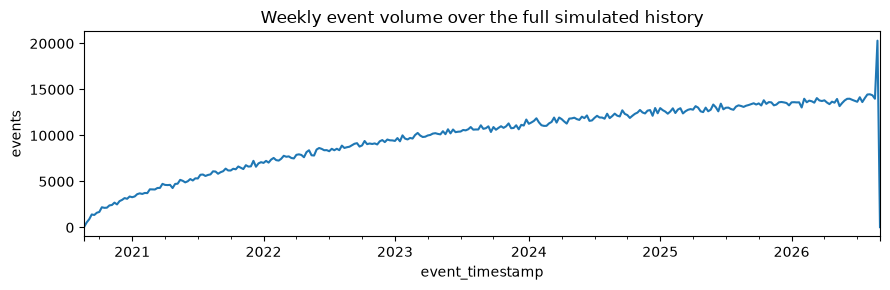


=== Final row counts ===
  users: 9,156
  subscriptions: 9,156
  payments: 227,990
  events: 3,095,843


In [26]:
# Retention sanity check: an OLD cohort must still have early-lifecycle events,
# or day-7/day-30 retention would silently read as zero for them.
old_user = raw.loc[raw['tenure'] >= 70, 'customerID'].iloc[0]
su = pd.Timestamp(users.loc[users.user_id == old_user, 'signup_date'].iloc[0])
early = events[(events.user_id == old_user) & (events.event_timestamp < su + pd.Timedelta(days=30))]
print(f"user {old_user} (tenure 70+ months, signed up {su.date()}): "
      f"{len(early)} events in their first 30 days -> retention math will work for this cohort")

# Funnel invariant: every paid user must be activated, or the funnel breaks
in_trial_features_check = events.loc[events['event_name'] == 'feature_used', ['user_id', 'event_timestamp']]
still_missing = paid_users[~paid_users['user_id'].isin(
    set(in_trial_features_check.merge(paid_users, on='user_id')
        .query('event_timestamp >= trial_start and event_timestamp < trial_end')['user_id'])
)]
assert len(still_missing) == 0, f"{len(still_missing)} paid users still have no in-trial activation event"
print("funnel invariant OK: every paid user has >=1 in-trial feature_used event")

# Churn-timing invariant: churned users' payment history should NOT cluster at
# the snapshot -- that was exactly the earlier bug (see Step 2). Most churned
# users' last payment should fall well before the snapshot month.
churned_ids = set(subscriptions.loc[(subscriptions['status'] == 'churned') & subscriptions['paid_date'].notna(), 'user_id'])
last_pay = payments[payments['user_id'].isin(churned_ids)].groupby('user_id')['payment_date'].max()
recent_cutoff = (SNAPSHOT_DATE - pd.DateOffset(months=2)).date()
pct_recent = 100 * (last_pay > recent_cutoff).mean()
print(f"{pct_recent:.1f}% of churned payers' last payment falls in the most recent 2 months "
      f"(should be a small minority, not the bulk of {len(churned_ids)} churned payers)")
assert pct_recent < 25, "churned users' payments are clustering at the snapshot again -- signup_date bug is back"

weekly = events.set_index('event_timestamp').resample('W').size()
fig, ax = plt.subplots(figsize=(9, 3))
weekly.iloc[:-1].plot(ax=ax)   # drop the trailing partial week
ax.set_title('Weekly event volume over the full simulated history')
ax.set_ylabel('events')
plt.tight_layout()
plt.show()

print()
print("=== Final row counts ===")
for name, df in [('users', users), ('subscriptions', subscriptions), ('payments', payments), ('events', events)]:
    print(f"  {name}: {len(df):,}")


## Step 8 - Save processed CSVs

Write the four tables to `data/processed/`. These large, reproducible files are excluded from Git; the source CSV and generation notebook are versioned.


In [27]:
os.makedirs(OUT_DIR, exist_ok=True)
users.to_csv(f'{OUT_DIR}/users.csv', index=False)
subscriptions.to_csv(f'{OUT_DIR}/subscriptions.csv', index=False)
payments.to_csv(f'{OUT_DIR}/payments.csv', index=False)
events.to_csv(f'{OUT_DIR}/events.csv', index=False)

for f in ['users.csv', 'subscriptions.csv', 'payments.csv', 'events.csv']:
    print(f"  {f}: {os.path.getsize(f'{OUT_DIR}/{f}')/1_000_000:.1f} MB")


  users.csv: 0.4 MB
  subscriptions.csv: 0.4 MB
  payments.csv: 8.0 MB
  events.csv: 232.1 MB


## Step 9 - Load PostgreSQL

Read connection settings from `.env` and import the CSVs with `COPY`, loading the parent table before its children. This cell replaces existing project data. The current implementation commits the truncation and imports separately; an atomic load remains a documented improvement.


In [28]:
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

load_dotenv('../.env', override=True)

db_url = URL.create(
    'postgresql+psycopg2',
    username=os.getenv('PGUSER'),
    password=os.getenv('PGPASSWORD', ''),
    host=os.getenv('PGHOST', 'localhost'),
    port=int(os.getenv('PGPORT', '5432')),
    database=os.getenv('PGDATABASE'),
)
engine = create_engine(db_url)

with engine.begin() as conn:
    conn.execute(text("TRUNCATE TABLE payments, events, subscriptions, users RESTART IDENTITY CASCADE;"))

def copy_csv(table, path):
    raw_conn = engine.raw_connection()
    try:
        cur = raw_conn.cursor()
        with open(path, 'r') as f:
            cur.copy_expert(f"COPY {table} FROM STDIN WITH (FORMAT csv, HEADER true)", f)
        raw_conn.commit()
    finally:
        raw_conn.close()

for table in ['users', 'subscriptions', 'payments', 'events']:  # parent before children
    copy_csv(table, f'{OUT_DIR}/{table}.csv')
    print(f"  loaded {table}")

with engine.begin() as conn:
    conn.execute(text(
        "SELECT setval(pg_get_serial_sequence('payments','payment_id'), "
        "COALESCE((SELECT MAX(payment_id) FROM payments), 1));"))
    conn.execute(text(
        "SELECT setval(pg_get_serial_sequence('events','event_id'), "
        "COALESCE((SELECT MAX(event_id) FROM events), 1));"))

print(f"\nDone in {time.time()-t0:.0f}s total")


  loaded users
  loaded subscriptions
  loaded payments
  loaded events

Done in 407s total


## Step 10 - Verify the load


In [29]:
display(pd.read_sql(text('''
    SELECT 'users' AS tbl, COUNT(*) AS n FROM users
    UNION ALL SELECT 'subscriptions', COUNT(*) FROM subscriptions
    UNION ALL SELECT 'payments', COUNT(*) FROM payments
    UNION ALL SELECT 'events', COUNT(*) FROM events
'''), engine))

display(pd.read_sql(text('''
    SELECT status, COUNT(*) AS users, COUNT(paid_date) AS converted
    FROM subscriptions GROUP BY status ORDER BY status
'''), engine))


,tbl,n
0,users,9156
1,subscriptions,9156
2,payments,227990
3,events,3095843


,status,users,converted
0,active,5174,5174
1,churned,3982,1869
